In [1]:
# 1. SETUP
import os, re, glob, warnings
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from scipy.stats import skew, kurtosis
import plotly.express as px
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

DATA_ROOT = os.environ.get("NINAPRO_ROOT", "/kaggle/input")
FS, WIN, SEED = 2000, 400, 42          # 2000 Hz, window = 400 samples (200 ms)
rng = np.random.default_rng(SEED)
CH = [f"ch{i:02d}" for i in range(1, 13)]

In [2]:
# 2. FIND FILES
pat = re.compile(r"S(\d+)_E(\d+)_A\d+\.mat$")
paths = sorted(glob.glob(f"{DATA_ROOT}/**/S*_E*_A*.mat", recursive=True))
files = pd.DataFrame([(p, int(m[1]), int(m[2])) for p in paths if (m := pat.search(p))],
                     columns=["path", "subject", "exercise"])
assert len(files) > 0, "No .mat files found"

print(f"Files: {len(files)} | Subjects: {files.subject.nunique()} | Exercises: {sorted(files.exercise.unique().tolist())}")
print(f"12 EMG channels, {FS} Hz, window = {WIN} samples = {WIN*1000//FS} ms")

Files: 120 | Subjects: 40 | Exercises: [1, 2, 3]
12 EMG channels, 2000 Hz, window = 400 samples = 200 ms


In [3]:
# 3. LOAD EVERYTHING ONCE (one file at a time, to save memory)
samples, wins, segs, n_bad, n_total = [], [], [], 0, 0

for f in files.itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    n_bad += int((~np.isfinite(emg)).sum()); n_total += emg.size

    # 4000 random raw samples (for stats + plots)
    s = pd.DataFrame(emg[rng.choice(len(emg), min(4000, len(emg)), replace=False)], columns=CH)
    s["subject"] = f.subject 
    samples.append(s)

    # one segment = one gesture in one repetition
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        segs.append((f.subject, f.exercise, int(lab[a]), b - a))
        if lab[a] > 0 and b - a >= WIN:                      # active gesture -> take 1 random window
            st = rng.integers(a, b - WIN + 1)
            wins.append((f.subject, f.exercise, int(lab[a]), np.sqrt((emg[st:st+WIN] ** 2).mean(0))))  # RMS per channel

samp = pd.concat(samples, ignore_index=True)
seg = pd.DataFrame(segs, columns=["subject", "exercise", "label", "length"])
win = pd.DataFrame([w[:3] for w in wins], columns=["subject", "exercise", "label"])
rms = pd.DataFrame([w[3] for w in wins], columns=CH)        # window feature = RMS of each channel

print(f"Loaded {len(files)} files, {n_total/12:,.0f} samples per channel")
print(f"Segments: {len(seg):,} | Windows used for analysis: {len(win):,} (RMS feature, 12 channels)")

Loaded 120 files, 207,713,115 samples per channel
Segments: 23,640 | Windows used for analysis: 11,760 (RMS feature, 12 channels)


In [4]:
# 4. SPLIT SUBJECTS (train / val / test) - do this BEFORE fitting anything
subj = rng.permutation(sorted(win.subject.unique()))
n_test, n_val = max(1, round(0.2 * len(subj))), max(1, round(0.1 * len(subj)))
test, val, train = subj[:n_test], subj[n_test:n_test + n_val], subj[n_test + n_val:]
assert not set(train) & set(val) and not set(train) & set(test) and not set(val) & set(test)

is_train = win.subject.isin(train).values
print("[OK] No subject appears in two groups (no leakage)")
print(f"train: {len(train)} subjects | val: {len(val)} subjects | test: {len(test)} subjects")
print(f"windows -> train: {is_train.sum():,} | val: {win.subject.isin(val).sum():,} | test: {win.subject.isin(test).sum():,}")
print("Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.")

# train-only views: every statistic / plot / fitted object in A-H comes from these
split    = np.where(is_train, "train", np.where(win.subject.isin(val), "val", "test"))
samp_tr  = samp[samp.subject.isin(train)][CH]       # raw samples, train subjects
win_tr   = win[is_train]                            # window labels, train subjects
rms_tr   = rms[is_train]                            # RMS features, train subjects
seg_tr   = seg[seg.subject.isin(train)]             # segments, train subjects

[OK] No subject appears in two groups (no leakage)
train: 28 subjects | val: 4 subjects | test: 8 subjects
windows -> train: 8,232 | val: 1,176 | test: 2,352
Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.


In [5]:
# quick look at the structure we just described
per_subj = win.groupby("subject").size()
print(f"Subjects: {win.subject.nunique()} | windows per subject: min {per_subj.min()}, mean {per_subj.mean():.0f}, max {per_subj.max()}")
print(f"Graph per sample: {len(CH)} nodes (one per electrode), 1 feature per node (window RMS)")
display(win.assign(split=split).groupby("split").agg(subjects=("subject", "nunique"), windows=("label", "size"), gestures=("label", "nunique")))

Subjects: 40 | windows per subject: min 294, mean 294, max 294
Graph per sample: 12 nodes (one per electrode), 1 feature per node (window RMS)


,subjects,windows,gestures
split,,,
test,8,2352,49
train,28,8232,49
val,4,1176,49


#  A. Dataset summary

In [6]:
# Descriptive only (all subjects): nothing is fitted here, so no leakage.
dup = int(files.duplicated(["subject", "exercise"]).sum())
act = seg[(seg.label > 0) & (seg.length >= WIN)]
cls_all = act.groupby(["exercise", "label"]).size().rename("n").reset_index()
ratio_all = cls_all.n.max() / cls_all.n.min()
rest = seg[seg.label == 0].length.sum() / seg.length.sum() * 100

summary = pd.Series({
    "Name": "NinaPro DB2",
    "Source": "ninapro.hevs.ch (Kaggle copy)",
    "Area": "Biomedical - sEMG hand gesture recognition",
    "Samples (time steps)": f"{n_total // 12:,} per channel",
    "Windows analysed": f"{len(win):,} (200 ms each)",
    "Classes": f"{len(cls_all)} gestures (+ rest)",
    "Features": "12 channels, RMS per window (numeric, continuous)",
    "Subjects": files.subject.nunique(),
    "Class balance": f"{ratio_all:.2f}x (max/min); rest = {rest:.0f}% of samples",
    "Missing values": f"{n_bad:,}",
    "Duplicate files": dup,
}, name="value").to_frame()
display(summary)

,value
Name,NinaPro DB2
Source,ninapro.hevs.ch (Kaggle copy)
Area,Biomedical - sEMG hand gesture recognition
Samples (time steps),"207,713,115 per channel"
Windows analysed,"11,760 (200 ms each)"
Classes,49 gestures (+ rest)
Features,"12 channels, RMS per window (numeric, continuous)"
Subjects,40
Class balance,1.00x (max/min); rest = 44% of samples
Missing values,0


# B. Data quality

In [7]:
# Statistical checks on TRAIN subjects only (missing/duplicate are integrity checks on all files)
std = samp_tr.std(); near_const = std[std < 0.01 * std.median()].index.tolist()
R = rms_tr.corr()
pairs = R.where(np.triu(np.ones(R.shape), 1) > 0).stack().sort_values(ascending=False)
high_corr = pairs[pairs > 0.9]

# Calculate outliers using IQR rule
q_out = samp_tr.quantile([0.25, 0.75])
iqr_out = q_out.loc[0.75] - q_out.loc[0.25]

outlier_iqr = (
    (samp_tr < q_out.loc[0.25] - 1.5 * iqr_out) |
    (samp_tr > q_out.loc[0.75] + 1.5 * iqr_out)
).mean() * 100

print(f"Missing values     : {n_bad / n_total * 100:.4f}%", "[OK]" if n_bad == 0 else "[!]")
print(f"Duplicate files    : {dup}", "[OK]" if dup == 0 else "[!]")
print(f"Near-constant chan.: {near_const or 'none'}", "[OK]" if not near_const else "[!]")
print(f"Highly correlated  : {len(high_corr)} channel pairs with r > 0.9", "[OK]" if len(high_corr) == 0 else "[!]")
print(f"Outliers (IQR rule): {outlier_iqr.mean():.1f}% of samples")

display(pd.DataFrame({"effect on modeling": [
    "Missing values -> need imputation/removal, otherwise training breaks (NaN loss).",
    "Duplicates -> same data in train and test inflates accuracy.",
    "Near-constant channel -> gives no information, can be dropped.",
    "Highly correlated channels -> redundant information, graph edges become dense.",
    "Outliers (EMG spikes) -> can dominate scaling; use robust or per-channel normalisation."]},
    index=["Missing", "Duplicates", "Near-constant", "High correlation", "Outliers"]))

Missing values     : 0.0000% [OK]
Duplicate files    : 0 [OK]
Near-constant chan.: none [OK]
Highly correlated  : 0 channel pairs with r > 0.9 [OK]
Outliers (IQR rule): 14.2% of samples


,effect on modeling
Missing,"Missing values -> need imputation/removal, oth..."
Duplicates,Duplicates -> same data in train and test infl...
Near-constant,"Near-constant channel -> gives no information,..."
High correlation,Highly correlated channels -> redundant inform...
Outliers,Outliers (EMG spikes) -> can dominate scaling;...


# C. Statistics

In [8]:
q = samp_tr.quantile([.25, .5, .75]).T
iqr = q[0.75] - q[0.25]
outlier_iqr = ((samp_tr < q[0.25] - 1.5 * iqr) | (samp_tr > q[0.75] + 1.5 * iqr)).mean() * 100

stats = pd.DataFrame({"mean": samp_tr.mean(), "median": q[0.5], "std": samp_tr.std(), "min": samp_tr.min(), "max": samp_tr.max(),
                      "Q1": q[0.25], "Q3": q[0.75], "skew": skew(samp_tr), "kurtosis": kurtosis(samp_tr), "outlier_%": outlier_iqr})
print("Statistics of raw samples, TRAIN subjects only (these decide normalisation).")
display(stats.round(3))
print("Read it: mean ~ 0 (EMG is a signed signal). Kurtosis > 0 = heavy tails (many spikes). Skew ~ 0 = symmetric.")

Statistics of raw samples, TRAIN subjects only (these decide normalisation).


,mean,median,std,min,max,Q1,Q3,skew,kurtosis,outlier_%
ch01,-0.0,0.0,0.0,-0.006,0.006,-0.0,0.0,-0.845,894.481995,18.552
ch02,0.0,0.0,0.0,-0.006,0.006,-0.0,0.0,10.280,5342.629883,16.420
ch03,-0.0,0.0,0.0,-0.002,0.001,-0.0,0.0,-3.104,263.134003,16.700
ch04,-0.0,0.0,0.0,-0.002,0.005,-0.0,0.0,18.552,3374.097900,15.505
ch05,0.0,0.0,0.0,-0.001,0.002,-0.0,0.0,10.617,2127.731934,7.795
ch06,-0.0,0.0,0.0,-0.001,0.001,-0.0,0.0,-0.144,533.565002,8.852
ch07,0.0,0.0,0.0,-0.009,0.006,-0.0,0.0,-2.523,1092.952026,16.829
ch08,0.0,0.0,0.0,-0.005,0.004,-0.0,0.0,-7.336,1133.743042,17.635
ch09,-0.0,-0.0,0.0,-0.003,0.004,-0.0,0.0,5.590,1284.354004,15.629
ch10,-0.0,0.0,0.0,-0.007,0.008,-0.0,0.0,0.616,1543.194946,17.386


Read it: mean ~ 0 (EMG is a signed signal). Kurtosis > 0 = heavy tails (many spikes). Skew ~ 0 = symmetric.


# D. Class balance

TRAIN subjects: imbalance 1.00x | all subjects: 1.00x  -> similar = split is representative
49 gesture classes | segments per class: min 168, max 168 | imbalance 1.00x
Effect on metrics: balanced -> accuracy is a fair metric.
Rest is 44% of raw samples, so it is excluded from the class counts (it would dominate accuracy).


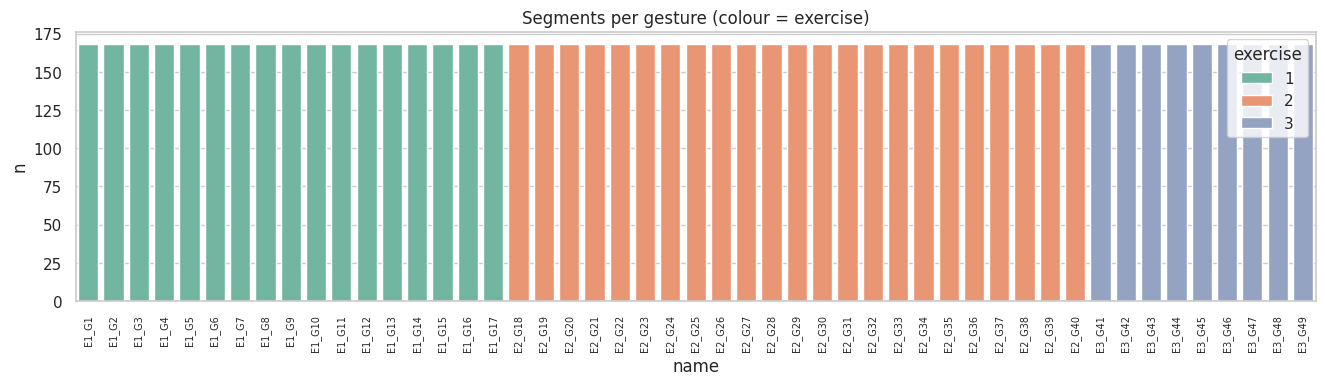

In [9]:
act_tr = seg_tr[(seg_tr.label > 0) & (seg_tr.length >= WIN)]
cls = act_tr.groupby(["exercise", "label"]).size().rename("n").reset_index()
cls["name"] = "E" + cls.exercise.astype(str) + "_G" + cls.label.astype(str)
ratio = cls.n.max() / cls.n.min()
rest = seg_tr[seg_tr.label == 0].length.sum() / seg_tr.length.sum() * 100

print(f"TRAIN subjects: imbalance {ratio:.2f}x | all subjects: {ratio_all:.2f}x  -> similar = split is representative")
print(f"{len(cls)} gesture classes | segments per class: min {cls.n.min()}, max {cls.n.max()} | imbalance {ratio:.2f}x")
print("Effect on metrics:", "balanced -> accuracy is a fair metric." if ratio < 1.5 else
      "imbalanced -> accuracy is misleading; use macro-F1 / balanced accuracy and class weights.")
print(f"Rest is {rest:.0f}% of raw samples, so it is excluded from the class counts (it would dominate accuracy).")

plt.figure(figsize=(16, 3.5))
sns.barplot(data=cls, x="name", y="n", hue="exercise", dodge=False, palette="Set2")
plt.xticks(rotation=90, fontsize=7); plt.title("Segments per gesture (colour = exercise)"); plt.show()

# E. Feature distributions (window RMS)

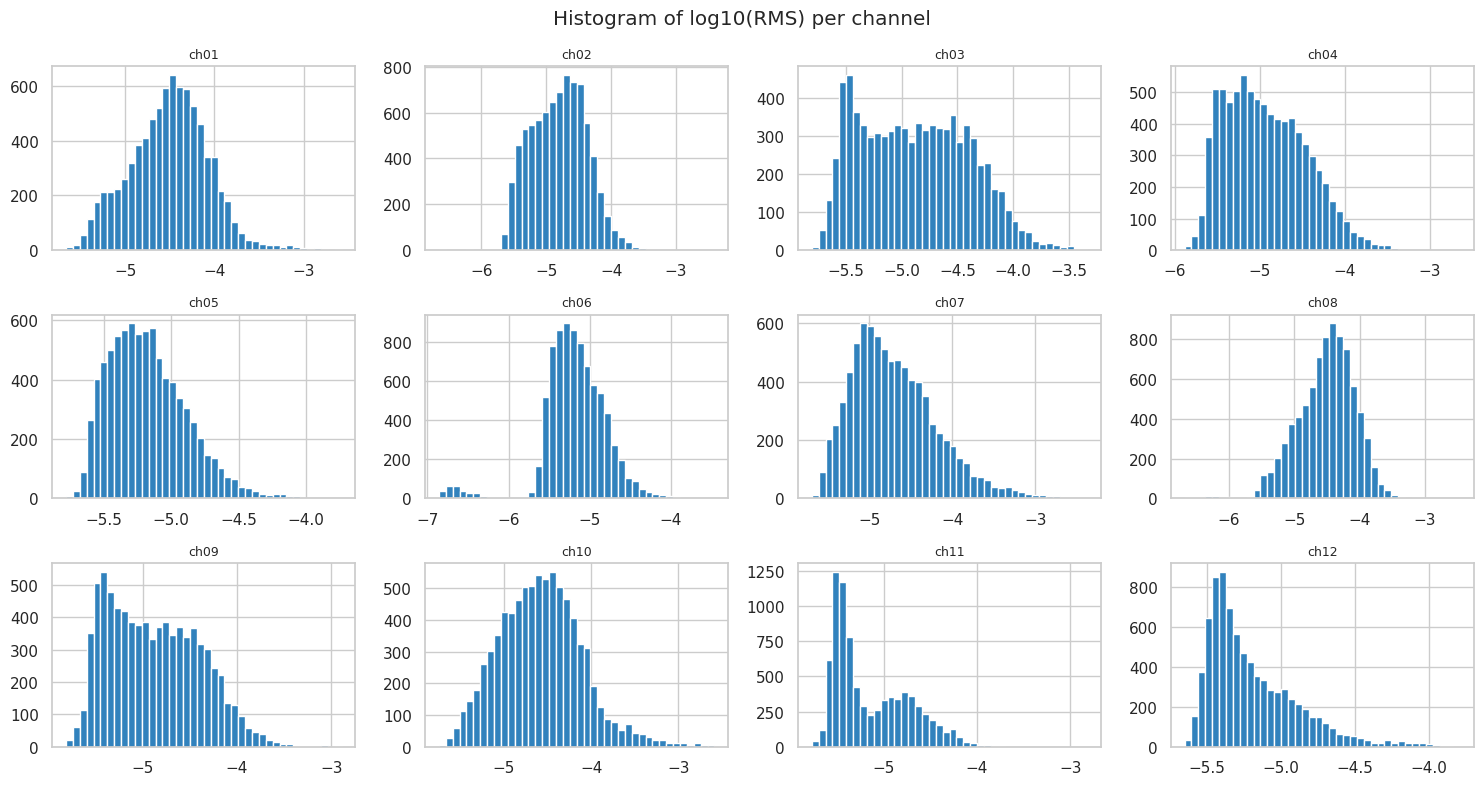

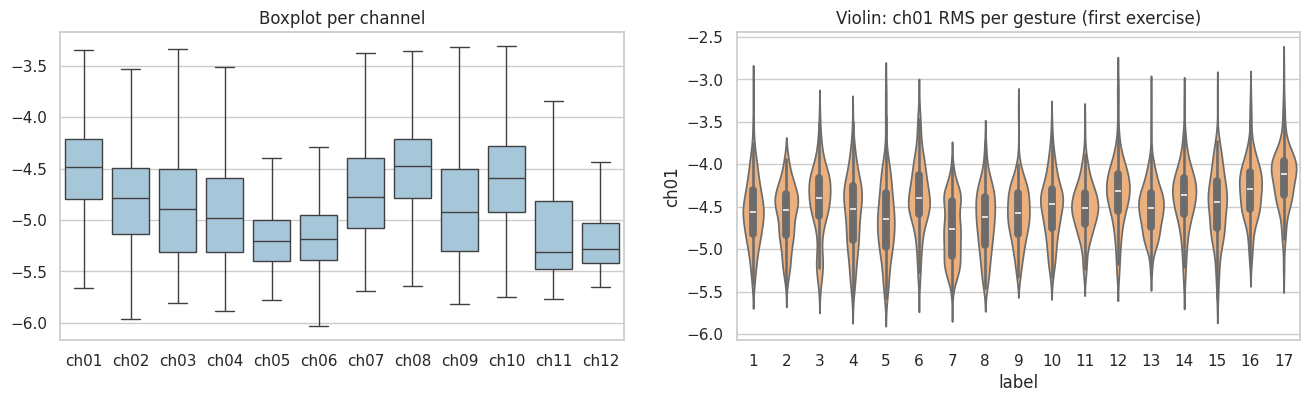

Gesture explains 15% of RMS variance on average; best channel ch11: 32%
Read it: if the violins look alike, single-channel RMS cannot separate gestures well; the pattern across channels matters.


In [10]:
logrms = np.log10(rms_tr + 1e-9)

fig, ax = plt.subplots(3, 4, figsize=(15, 8))
for a, c in zip(ax.ravel(), CH):
    a.hist(logrms[c], bins=40, color="#3182bd"); a.set_title(c, fontsize=9)
fig.suptitle("Histogram of log10(RMS) per channel"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(data=logrms, ax=ax[0], showfliers=False, color="#9ecae1"); ax[0].set_title("Boxplot per channel")
e1 = win_tr.exercise == win_tr.exercise.min()
sns.violinplot(x=win_tr.label[e1], y=logrms["ch01"][e1], ax=ax[1], color="#fdae6b")
ax[1].set_title("Violin: ch01 RMS per gesture (first exercise)"); plt.show()

# do classes separate? eta^2 = share of variance explained by the gesture label (0 = none, 1 = perfect)
cls_id = win_tr.exercise.astype(str) + "_" + win_tr.label.astype(str)
eta = {c: logrms[c].groupby(cls_id).transform("mean").var() / logrms[c].var() for c in CH}
best = max(eta, key=eta.get)
print(f"Gesture explains {np.mean(list(eta.values()))*100:.0f}% of RMS variance on average; best channel {best}: {eta[best]*100:.0f}%")
print("Read it: if the violins look alike, single-channel RMS cannot separate gestures well; the pattern across channels matters.")

# E2. Class x channel pattern (one exercise)

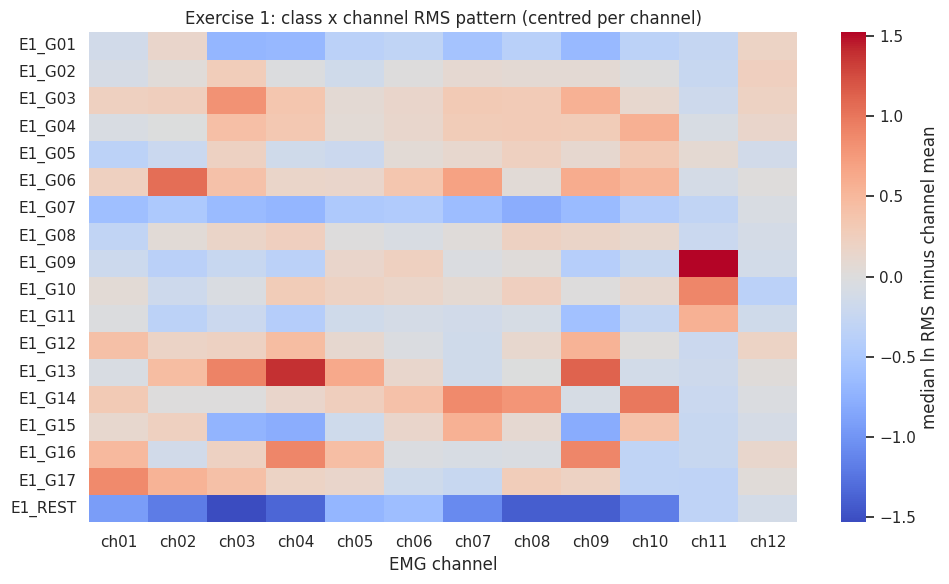

Strongest deviation: E1_REST on ch03 (-1.53 ln-units, about 4.6x vs. that channel's average)
Read it: red = channel is more active than its own average for that class, blue = less active.
Rows with different red/blue patterns = gestures can be told apart by the pattern across channels.


In [11]:
# Class x channel RMS pattern for one exercise (centred per channel)
ex = win.exercise.min()                                   # same exercise as the violin plot above

# `win` only holds active gestures, so cut REST windows from this exercise's files (train subjects only)
rest_rng = np.random.default_rng(SEED)                    # own generator -> earlier random results stay unchanged
rest_rows = []
for f in files[(files.exercise == ex) & files.subject.isin(train)].itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        if lab[a] == 0 and b - a >= WIN:                  # rest segment -> 1 random window
            st = rest_rng.integers(a, b - WIN + 1)
            rest_rows.append(np.sqrt((emg[st:st + WIN] ** 2).mean(0)))

# median ln(RMS) per class and channel
use = is_train & (win.exercise == ex).values
med = np.log(rms[use] + 1e-9).groupby(win.label[use].values).median()
med.index = [f"E{ex}_G{g:02d}" for g in med.index]
med.loc[f"E{ex}_REST"] = np.log(pd.DataFrame(rest_rows, columns=CH) + 1e-9).median()

pattern = med - med.mean()                                # centre every channel (column) at 0

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pattern, cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "median ln RMS minus channel mean"})
ax.set_title(f"Exercise {ex}: class x channel RMS pattern (centred per channel)")
ax.set_xlabel("EMG channel"); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

r, c = np.unravel_index(np.abs(pattern.values).argmax(), pattern.shape)
print(f"Strongest deviation: {pattern.index[r]} on {pattern.columns[c]} ({pattern.iat[r, c]:+.2f} ln-units, "
      f"about {np.exp(abs(pattern.iat[r, c])):.1f}x vs. that channel's average)")
print("Read it: red = channel is more active than its own average for that class, blue = less active.")
print("Rows with different red/blue patterns = gestures can be told apart by the pattern across channels.")

# F. Correlation

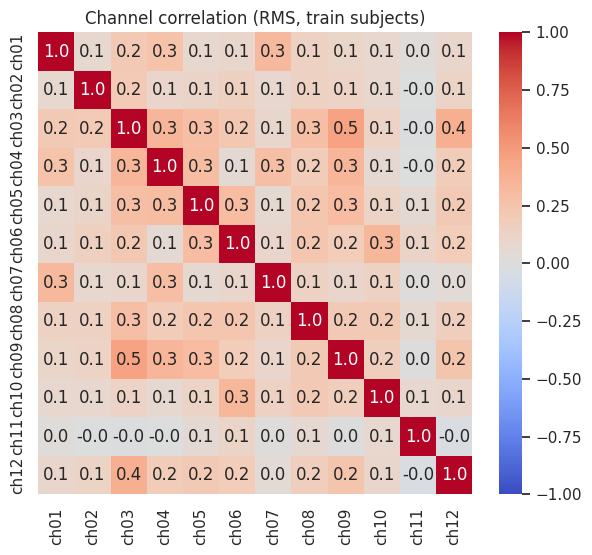

Average correlation: 0.16
Redundant channel pairs (r > 0.9): none
Top 3 pairs: ch03-ch09 (0.46), ch03-ch12 (0.39), ch04-ch09 (0.35)


In [12]:
plt.figure(figsize=(7, 6)); sns.heatmap(R, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Channel correlation (RMS, train subjects)"); plt.show()

print(f"Average correlation: {pairs.mean():.2f}")
print("Redundant channel pairs (r > 0.9):", [f"{a}-{b} ({v:.2f})" for (a, b), v in high_corr.items()] or "none")
print("Top 3 pairs:", ", ".join(f"{a}-{b} ({v:.2f})" for (a, b), v in pairs.head(3).items()))

# G. 2D / 3D view: PCA, t-SNE, UMAP

PCA variance explained: ['47%', '12%', '9%']


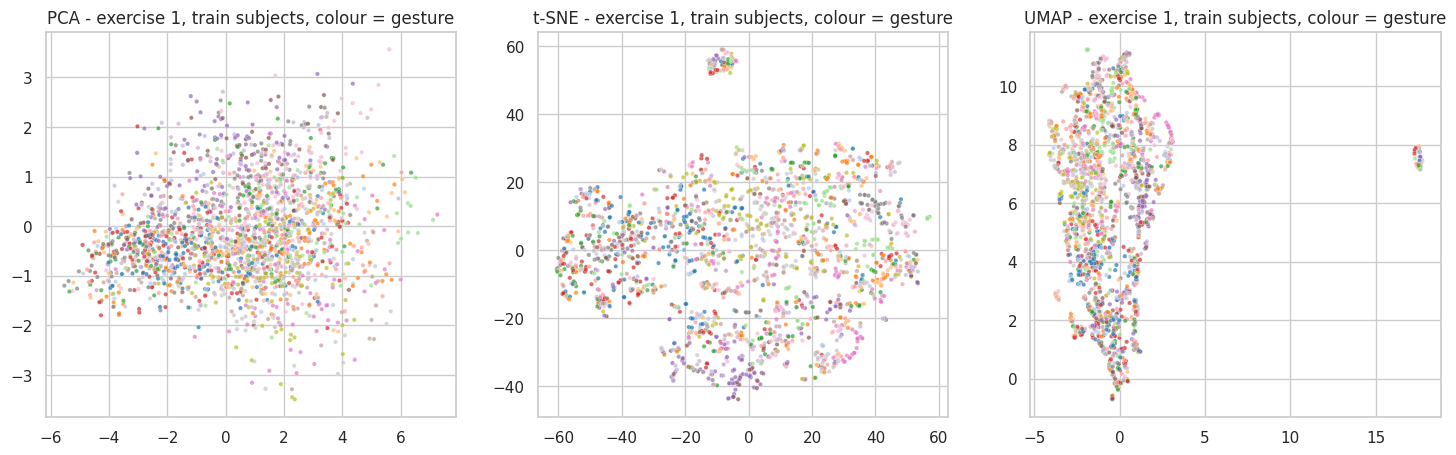

Do classes separate? (silhouette: 1 = clearly separated, 0 = overlapping, <0 = mixed)
  PCA -0.20 | t-SNE -0.20 | UMAP -0.19


In [13]:
Z = StandardScaler().fit(np.log(rms[is_train])).transform(np.log(rms))
pca = PCA(3).fit(Z[is_train]); P = pca.transform(Z)
print("PCA variance explained:", [f"{v*100:.0f}%" for v in pca.explained_variance_ratio_])

# t-SNE / UMAP on one exercise (gestures of different exercises are not comparable)
ex = win.exercise.min()
pool = np.flatnonzero((win.exercise == ex).values & is_train)      # TRAIN windows of this exercise
idx = rng.choice(pool, min(2000, len(pool)), replace=False)
y = win.label.values[idx]
T = TSNE(2, perplexity=min(30, len(idx) // 4), random_state=SEED).fit_transform(Z[idx])
try:
    import umap; U = umap.UMAP(random_state=SEED).fit_transform(Z[idx])
except ImportError:
    U = None; print("(umap-learn not installed: pip install umap-learn)")

fig, ax = plt.subplots(1, 3 if U is not None else 2, figsize=(18, 5))
for a, (E, name) in zip(ax, [(P[idx, :2], "PCA"), (T, "t-SNE"), (U, "UMAP")]):
    if E is None: continue
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y, palette="tab20", s=10, alpha=.7, ax=a, legend=False)
    a.set_title(f"{name} - exercise {ex}, train subjects, colour = gesture")
plt.show()

print("Do classes separate? (silhouette: 1 = clearly separated, 0 = overlapping, <0 = mixed)")
print(f"  PCA {silhouette_score(P[idx, :2], y):.2f} | t-SNE {silhouette_score(T, y):.2f}" +
      (f" | UMAP {silhouette_score(U, y):.2f}" if U is not None else ""))

# H. Interactive plots (hover, zoom, click legend)

In [14]:
d = win.assign(PC1=P[:, 0], PC2=P[:, 1], PC3=P[:, 2], gesture=win.exercise.astype(str) + "_G" + win.label.astype(str), split=split)
d = d.sample(min(4000, len(d)), random_state=SEED)

px.scatter(d, x="PC1", y="PC2", color=d.exercise.astype(str), hover_data=["subject", "gesture"],
           title="PCA 2D - colour = exercise").show()
print("Zoom in and hover to see subject and gesture.")

px.scatter(d, x="PC1", y="PC2", color="split", hover_data=["subject", "gesture"], opacity=.6,
           title="PCA 2D - colour = split (PCA fitted on train only)").show()
print("val/test points inside the train cloud = little subject shift; a separate cloud = hard cross-subject problem.")

px.scatter_3d(d, x="PC1", y="PC2", z="PC3", color=d.exercise.astype(str), opacity=.6,
              title="PCA 3D - rotate with the mouse").show()
print("A third component adds separation only if clouds that overlap in 2D split apart here.")

Zoom in and hover to see subject and gesture.


val/test points inside the train cloud = little subject shift; a separate cloud = hard cross-subject problem.


A third component adds separation only if clouds that overlap in 2D split apart here.


# Summary

In [15]:
print(f"Data       : {len(files)} files, {files.subject.nunique()} subjects, 12 channels, {len(win):,} windows")
print(f"Quality    : missing={n_bad}, duplicates={dup}, near-constant={len(near_const)}, correlated pairs>0.9={len(high_corr)}")
print(f"Classes    : {len(cls_all)} gestures, imbalance {ratio_all:.2f}x (all subjects) / {ratio:.2f}x (train)")
print(f"Split      : {len(train)}/{len(val)}/{len(test)} subjects (train/val/test), no leakage")
print(f"Separation : gesture explains {np.mean(list(eta.values()))*100:.0f}% of RMS variance (avg per channel)")
print("All statistics, class balance and feature plots above are computed on TRAIN subjects only.")

Data       : 120 files, 40 subjects, 12 channels, 11,760 windows
Quality    : missing=0, duplicates=0, near-constant=0, correlated pairs>0.9=0
Classes    : 49 gestures, imbalance 1.00x (all subjects) / 1.00x (train)
Split      : 28/4/8 subjects (train/val/test), no leakage
Separation : gesture explains 15% of RMS variance (avg per channel)
All statistics, class balance and feature plots above are computed on TRAIN subjects only.
